# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
# Twoje rozwiązanie

import pandas as pd

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]

df = pd.read_csv(URL, names=kolumny)



print(df.shape)

display(df.head())

display(df.describe())


(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
dtype: int64


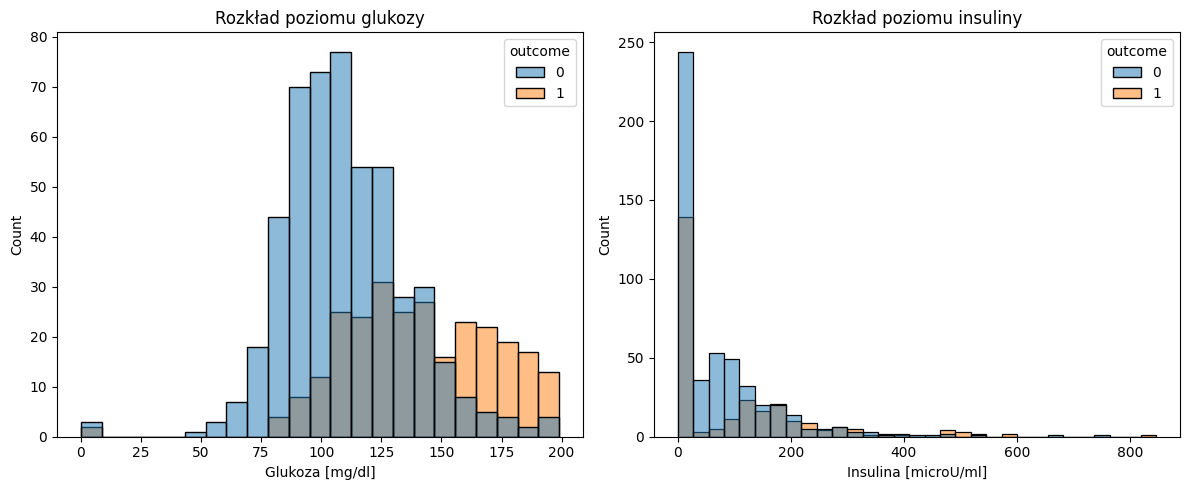

In [3]:
# Twoje rozwiązanie

import matplotlib.pyplot as plt
import seaborn as sns

class_share = df["outcome"].value_counts(normalize=True).sort_index()
print(class_share)

print(df.isna().sum())

zeros = (df.drop(columns=["outcome"]) == 0).sum()
print(zeros)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
axes[0].set_title("Rozkład poziomu glukozy")
axes[0].set_xlabel("Glukoza [mg/dl]")

sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])
axes[1].set_title("Rozkład poziomu insuliny")
axes[1].set_xlabel("Insulina [microU/ml]")

plt.tight_layout()
plt.show()


In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

*Twoja odpowiedź:*

1. Baseline osiąga 65,1%.

2. Zero jest niemożliwe w poziomie glukozy we krwii, ciśnieniu krwii, grubości fałdu skórnego, stężeniu insuliny, bmi, zera w pregnancies są zupełnie normalne, bo kobieta może nigdy nie być w ciąży.

3. Glukoza, pacjentki chore mają zazwyczj wyższe stężenie glukozy.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
# Twoje rozwiązanie

import numpy as np

kolumny_z_brakami = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]

df_clean = df.copy()
df_clean[kolumny_z_brakami] = df_clean[kolumny_z_brakami].replace(0, np.nan)

missing = df_clean.isna().sum()
print(missing)


pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Można usunąć wiersze z brakami, ale wtedy straci się prawie połowę danych. Można usunąć całą kolumnę z insuliną albo uzupełnić braki medianą. Wybieram uzupełnienie medianą, bo nie traci się żadnych pacjentek, a mediana jest lepsza od średniej, bo rozkład insuliny jest mocno skośny.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
# Twoje rozwiązanie

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = df_clean.drop(columns=["outcome"])
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)


def model_z(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), klasyfikator)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


(576, 8) (192, 8)


In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

,CV średnia,CV odch.,train
baseline,0.651,0.002,0.651
regresja logistyczna,0.778,0.025,0.790
kNN,0.736,0.021,0.835
drzewo decyzyjne,0.714,0.024,1.000
las losowy,0.748,0.014,1.000


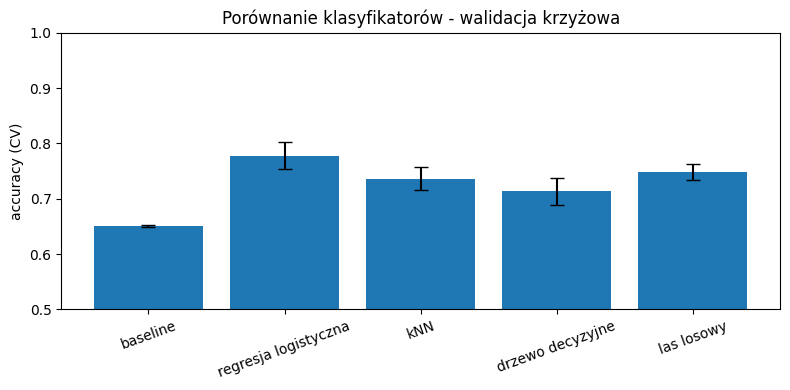

In [9]:
# Twoje rozwiązanie

from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modele = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42),
}

wiersze = {}
for nazwa, klf in modele.items():
    m = model_z(klf)
    wyniki_cv = cross_val_score(m, X_train, y_train, cv=cv)
    m.fit(X_train, y_train)
    wiersze[nazwa] = {
        "CV średnia": wyniki_cv.mean(),
        "CV odch.": wyniki_cv.std(),
        "train": m.score(X_train, y_train),
    }

porownanie = pd.DataFrame(wiersze).T
display(porownanie.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(porownanie.index, porownanie["CV średnia"], yerr=porownanie["CV odch."], capsize=5)
ax.set_ylim(0.5, 1)
ax.set_ylabel("accuracy (CV)")
ax.set_title("Porównanie klasyfikatorów - walidacja krzyżowa")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

    k  trening  walidacja
0   1    1.000      0.689
1   3    0.862      0.734
2   5    0.841      0.736
3   7    0.827      0.740
4  11    0.816      0.771
5  15    0.808      0.778
6  21    0.801      0.769
7  31    0.783      0.771
8  51    0.768      0.753


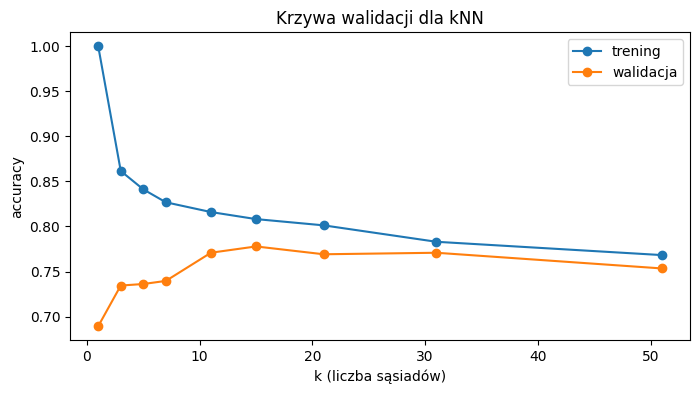

In [11]:
# Twoje rozwiązanie

from sklearn.model_selection import validation_curve

ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

tren, walid = validation_curve(
    model_z(KNeighborsClassifier()), X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv
)

print(pd.DataFrame({"k": ks, "trening": tren.mean(axis=1), "walidacja": walid.mean(axis=1)}).round(3))

plt.figure(figsize=(8, 4))
plt.plot(ks, tren.mean(axis=1), marker="o", label="trening")
plt.plot(ks, walid.mean(axis=1), marker="o", label="walidacja")
plt.xlabel("k (liczba sąsiadów)")
plt.ylabel("accuracy")
plt.title("Krzywa walidacji dla kNN")
plt.legend()
plt.show()


In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

Dla k = 1 najbliższym sąsiadem każdego punktu treningowego jest on sam (odległość 0), więc model zawsze zwraca jego własną etykietę i ma 100% na treningu. Na walidacji ma tylko 0,689, czyli jest mocno przeuczony, bo uczy się danych na pamięć. Przeuczenie jest dla małych k (1–7), gdzie trening jest dużo wyżej niż walidacja. Najlepiej wychodzi k ok. 11–31 (walidacja ok. 0,77–0,78). Dla dużego k (51) oba wyniki zaczynają spadać i się zbliżają, model robi się za prosty, czyli zaczyna się niedouczenie.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
# Twoje rozwiązanie

from sklearn.model_selection import GridSearchCV

siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa}: {gs.best_params_}, best_score_ = {gs.best_score_:.3f}")


regresja logistyczna: {'logisticregression__C': 1}, best_score_ = 0.778
kNN: {'kneighborsclassifier__n_neighbors': 15}, best_score_ = 0.778
drzewo decyzyjne: {'decisiontreeclassifier__max_depth': 5}, best_score_ = 0.750
las losowy: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}, best_score_ = 0.762


In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

najlepszy model: regresja logistyczna {'logisticregression__C': 1}
CV: 0.778
accuracy na teście: 0.724


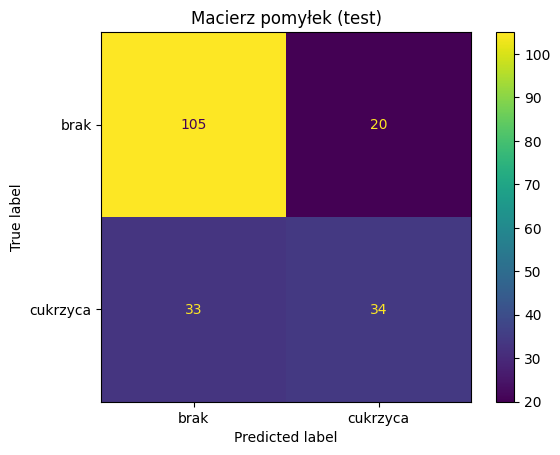

              precision    recall  f1-score   support

        brak      0.761     0.840     0.798       125
    cukrzyca      0.630     0.507     0.562        67

    accuracy                          0.724       192
   macro avg      0.695     0.674     0.680       192
weighted avg      0.715     0.724     0.716       192



In [15]:
# Twoje rozwiązanie

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print("najlepszy model:", najlepszy, wyniki_gs[najlepszy].best_params_)
print(f"CV: {wyniki_gs[najlepszy].best_score_:.3f}")

acc_test = model_koncowy.score(X_test, y_test)
print(f"accuracy na teście: {acc_test:.3f}")

y_pred = model_koncowy.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["brak", "cukrzyca"])
plt.title("Macierz pomyłek (test)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["brak", "cukrzyca"], digits=3))


In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

*Twoja odpowiedź:*

1. Najlepiej wyszła regresja logistyczna. W CV miała 0,778, a na teście 0,724, czyli o ok. 5,4 p.p. mniej. Jedna pacjentka to ok. 0,52 p.p., więc to różnica ok. 10 osób. Nie niepokoi mnie to bardzo, bo zbiór testowy jest mały, odchylenie w CV to ok. 2,5 p.p., a model i tak jest lepszy od baseline'u (0,651).

2. Recall dla cukrzycy to 0,507, czyli model wykrył tylko 34 z 67 chorych pacjentek, a resztę uznał za zdrowe. W medycynie to słabo, bo niewykryta cukrzyca jest dużo gorsza niż fałszywy alarm (który i tak sprawdzi się kolejnym badaniem). Accuracy nie jest tu dobrą metryką, bo klasy są niezbalansowane i ważniejsze jest wykrycie chorych, więc lepiej wybierać model po recall, albo F1.

3. Nie da się. Regresja logistyczna i kNN mają w CV tyle samo (0,778), a las losowy 0,762. Różnice są mniejsze niż odchylenia, więc przy innym podziale kolejność mogłaby wyjść inna.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
# 9.1 - GridSearchCV z scoring="recall"

from sklearn.metrics import recall_score, precision_score

wyniki_gs_recall = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs_recall[nazwa] = gs
    print(f"{nazwa}: {gs.best_params_}, recall (CV) = {gs.best_score_:.3f}")

najlepszy_recall = max(wyniki_gs_recall, key=lambda n: wyniki_gs_recall[n].best_score_)
model_recall = wyniki_gs_recall[najlepszy_recall].best_estimator_
print("\nnajlepszy model wg recall:", najlepszy_recall, wyniki_gs_recall[najlepszy_recall].best_params_)

y_pred_recall = model_recall.predict(X_test)
print(pd.DataFrame({
    "accuracy": [acc_test, model_recall.score(X_test, y_test)],
    "recall": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_recall)],
    "precision": [precision_score(y_test, y_pred), precision_score(y_test, y_pred_recall)],
}, index=[f"wg accuracy ({najlepszy})", f"wg recall ({najlepszy_recall})"]).round(3))


regresja logistyczna: {'logisticregression__C': 1}, recall (CV) = 0.583
kNN: {'kneighborsclassifier__n_neighbors': 3}, recall (CV) = 0.597
drzewo decyzyjne: {'decisiontreeclassifier__max_depth': 4}, recall (CV) = 0.652
las losowy: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}, recall (CV) = 0.582

najlepszy model wg recall: drzewo decyzyjne {'decisiontreeclassifier__max_depth': 4}
                                    accuracy  recall  precision
wg accuracy (regresja logistyczna)     0.724   0.507      0.630
wg recall (drzewo decyzyjne)           0.750   0.612      0.651


*Twoja odpowiedź:* Tak, wybrany model się zmienił. Teraz najlepsze jest drzewo decyzyjne (max_depth = 4), a wcześniej była regresja logistyczna. Recall na teście wzrósł z 0,507 do 0,612. Precision nie spadła, tylko trochę wzrosła z 0,630 do 0,651.

In [18]:
# 9.2 - flagi braków (add_indicator=True)

def model_z_flagami(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), klasyfikator)


flagi = {}
for nazwa, klf in list(modele.items())[1:]:
    flagi[nazwa] = {
        "bez flag": cross_val_score(model_z(klf), X_train, y_train, cv=cv).mean(),
        "z flagami": cross_val_score(model_z_flagami(klf), X_train, y_train, cv=cv).mean(),
    }
display(pd.DataFrame(flagi).T.round(3))

# wagi regresji logistycznej - czy flaga braku insuliny coś znaczy?
lr_flagi = model_z_flagami(LogisticRegression()).fit(X_train, y_train)
nazwy = lr_flagi.named_steps["simpleimputer"].get_feature_names_out()
print(pd.Series(lr_flagi.named_steps["logisticregression"].coef_[0], index=nazwy).sort_values().round(3))

# odsetek chorych wśród pacjentek z brakiem insuliny i z pomiarem
print(df_clean.groupby(df_clean["insulin"].isna())["outcome"].mean().round(3))


,bez flag,z flagami
regresja logistyczna,0.778,0.767
kNN,0.736,0.741
drzewo decyzyjne,0.714,0.708
las losowy,0.748,0.750


missingindicator_bmi              -0.094
missingindicator_skin_thickness   -0.089
blood_pressure                    -0.071
skin_thickness                    -0.065
insulin                            0.004
missingindicator_glucose           0.067
age                                0.124
missingindicator_insulin           0.190
missingindicator_blood_pressure    0.202
pedigree                           0.235
pregnancies                        0.433
bmi                                0.739
glucose                            1.178
dtype: float64
insulin
False    0.330
True     0.369
Name: outcome, dtype: float64


*Twoja odpowiedź:* Flagi braków prawie nic nie zmieniają, wyniki w CV różnią się o mniej niż 1 p.p. Sam brak pomiaru insuliny niesie bardzo mało informacji. Wśród pacjentek bez pomiaru insuliny chorych jest 36,9%, a wśród tych z pomiarem 33,0%.

In [19]:
# 9.3 - zera zostawione zamiast NaN

X_zera = df.drop(columns=["outcome"])
X_train_zera, X_test_zera, y_train_zera, y_test_zera = train_test_split(
    X_zera, df["outcome"], test_size=0.25, stratify=df["outcome"], random_state=42
)

zera_vs_nan = {}
for nazwa, klf in list(modele.items())[1:]:
    zera_vs_nan[nazwa] = {
        "NaN + mediana": cross_val_score(model_z(klf), X_train, y_train, cv=cv).mean(),
        "zera": cross_val_score(model_z(klf), X_train_zera, y_train_zera, cv=cv).mean(),
    }
porownanie_zera = pd.DataFrame(zera_vs_nan).T
porownanie_zera["różnica"] = porownanie_zera["NaN + mediana"] - porownanie_zera["zera"]
porownanie_zera.round(3)


,NaN + mediana,zera,różnica
regresja logistyczna,0.778,0.778,0.000
kNN,0.736,0.734,0.002
drzewo decyzyjne,0.714,0.679,0.035
las losowy,0.748,0.755,-0.007


*Twoja odpowiedź:* Różnica jest mała. Dla regresji logistycznej wynik jest taki sam (0,778), dla kNN i lasu losowego różnica jest mniejsza niż 1 p.p., tylko drzewo decyzyjne spadło z 0,714 do 0,679. Różnica może być mała, bo glukoza, która jest najważniejszą cechą, ma tylko 5 zer, a insulina i grubość skóry, gdzie zer jest najwięcej, i tak mało wpływają na wynik. Poza tym zero jest daleko od normalnych wartości, więc model może je traktować jak osobną grupę.